In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Housing.csv')

In [3]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [43]:
df.shape

(545, 13)

In [4]:
df[["area", "price"]].describe()

,area,price
count,545.000000,5.450000e+02
mean,5150.541284,4.766729e+06
std,2170.141023,1.870440e+06
min,1650.000000,1.750000e+06
25%,3600.000000,3.430000e+06
50%,4600.000000,4.340000e+06
75%,6360.000000,5.740000e+06
max,16200.000000,1.330000e+07


In [5]:
df[["area", "price"]].isnull().sum()

area     0
price    0
dtype: int64

In [8]:
x = df["area"].values
y = df["price"].values

print(x[1])
print(y[1])

8960
12250000


In [10]:
x_max = x.max()
y_max = y.max()

x = x/x_max
y = y/y_max

In [12]:
print(x[:5])
print(y[:5])

[0.45802469 0.55308642 0.61481481 0.46296296 0.45802469]
[1.         0.92105263 0.92105263 0.91842105 0.85789474]


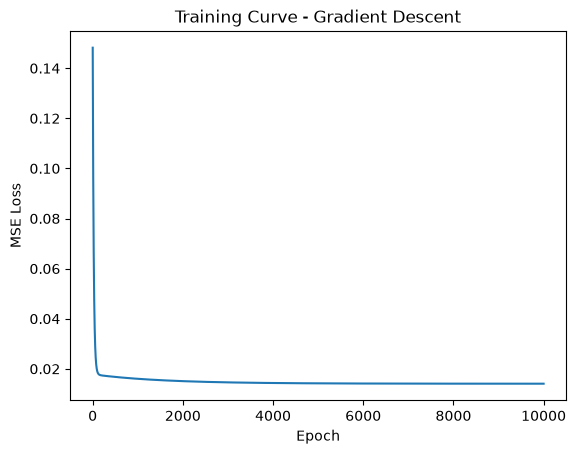

Intercept = 0.18522802952991832
Slope = 0.544972872103187
Predicted price = 4700612.792430749
mse = 0.014075749529637244


In [39]:
b0 = 0.0
b1 = 0.0

# Equation: y = b0 + b1*x

lr = 0.01
epochs = 10000
n = len(x)

loss_history = []

for i in range(epochs):
    y_pred = b0 + b1 * x

    error = y_pred - y

    loss = np.mean(error ** 2)
    loss_history.append(loss)

    db0 = (2/n) * np.sum(error)
    db1 = (2/n) * np.sum(error * x)

    b0 = b0 - lr * db0
    b1 = b1 - lr * db1

plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Curve - Gradient Descent")
plt.show()

print("Intercept =", b0)
print("Slope =", b1)

area = 5000
area_scaled = area / x_max

pred = b0 + b1 * area_scaled
price = pred * y_max

print("Predicted price =", price)

# Final MSE
y_pred = b0 + b1 * x
mse = np.mean((y_pred - y) ** 2)

print("mse =", mse)

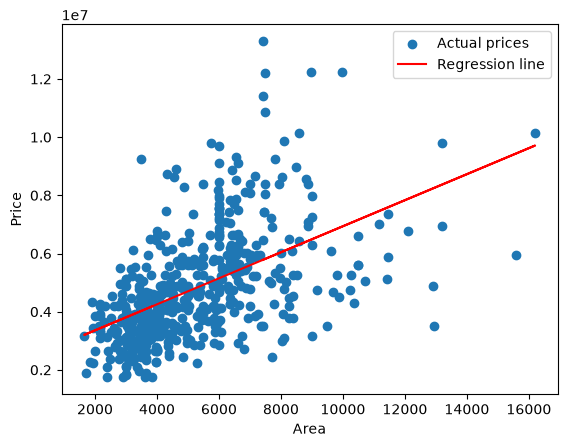

In [35]:
import matplotlib.pyplot as plt

x_original = x * x_max

plt.scatter(x_original, y * y_max, label="Actual prices")
plt.plot(x_original, y_pred * y_max, color="red", label="Regression line")

plt.xlabel("Area")
plt.ylabel("Price")
plt.legend()
plt.show()

In [36]:

for i in range(5):
    print("actual : " ,y[i] * y_max)
    print("predicted : ", y_pred[i] * y_max)
    print("diff: " ,(y[i] * y_max) - (y_pred[i] * y_max) )
    print()

actual :  13300000.0
predicted :  5783359.512277242
diff:  7516640.487722758

actual :  12250000.0
predicted :  6472380.152179554
diff:  5777619.847820446

actual :  12250000.0
predicted :  6919796.152116123
diff:  5330203.847883877

actual :  12215000.0
predicted :  5819152.792272167
diff:  6395847.207727833

actual :  11410000.0
predicted :  5783359.512277242
diff:  5626640.487722758



In [37]:
from sklearn.metrics import r2_score

r2_score(y, y_pred)

0.28700738709995166

In [41]:
q1 = df["area"].quantile(0.25)
q3 = df["area"].quantile(0.75)

iqr = q3 - q1

lower = q1 - iqr * 1.5
upper = q3 + iqr * 1.5

print("lower : ", lower)
print("upper : ", upper)
print("outliers : ", ((df["area"] < lower) | (df["area"] > upper)).sum())

lower :  -540.0
upper :  10500.0
outliers :  12


In [46]:
df_clean = df.copy()

for col in ["area", "price"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    
    iqr = q3 - q1
    
    lower = q1 - iqr * 1.5
    upper = q3 + iqr * 1.5
    
    df_clean = df_clean[ (df_clean[col] >= lower) &  (df_clean[col] <= upper)]

print("original :", len(df))
print("after removing outliers:", len(df_clean))

original : 545
after removing outliers: 518


In [47]:
X = df_clean["area"].values
y = df_clean["price"].values

x_max = X.max()
y_max = y.max()

x = X / x_max
y = y / y_max

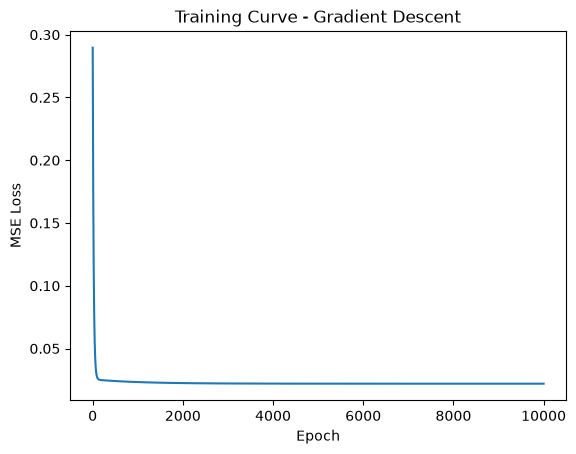

Intercept = 0.2581003508318283
Slope = 0.5355110035690487
Predicted price = 4597426.092014455
mse = 0.02199075891747657


In [48]:
b0 = 0.0
b1 = 0.0

# Equation: y = b0 + b1*x

lr = 0.01
epochs = 10000
n = len(x)

loss_history = []

for i in range(epochs):
    y_pred = b0 + b1 * x

    error = y_pred - y

    loss = np.mean(error ** 2)
    loss_history.append(loss)

    db0 = (2/n) * np.sum(error)
    db1 = (2/n) * np.sum(error * x)

    b0 = b0 - lr * db0
    b1 = b1 - lr * db1

plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Curve - Gradient Descent")
plt.show()

print("Intercept =", b0)
print("Slope =", b1)

area = 5000
area_scaled = area / x_max

pred = b0 + b1 * area_scaled
price = pred * y_max

print("Predicted price =", price)

# Final MSE
y_pred = b0 + b1 * x
mse = np.mean((y_pred - y) ** 2)

print("mse =", mse)

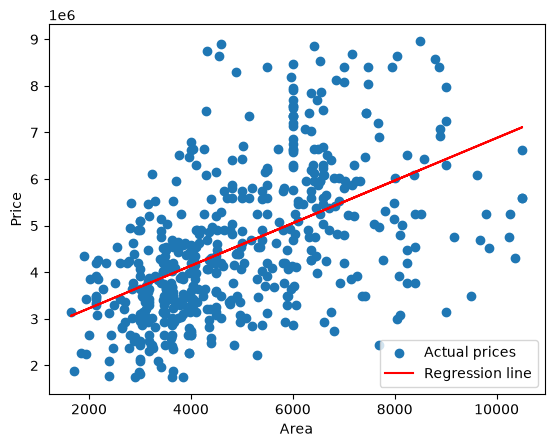

In [49]:
import matplotlib.pyplot as plt

x_original = x * x_max

plt.scatter(x_original, y * y_max, label="Actual prices")
plt.plot(x_original, y_pred * y_max, color="red", label="Regression line")

plt.xlabel("Area")
plt.ylabel("Price")
plt.legend()
plt.show()

In [50]:
from sklearn.metrics import r2_score

r2_score(y, y_pred)

0.2842201646164898